In [1]:
from solver.energy import TemperatureModule
from solver.simple import SIMPLEcfd
from core.mesh import Mesh
from core.material import Material
from core.settings import SolveSettings, PlotSettings
from core.fields import FlowField, FaceField
import pprint

import numpy as np

In [2]:
x = 0.9*1e-3# in [m]
y = 0.5*1e-3
z = 0.5*1e-3
nx = 50
nz = 50
dt = 1e-6

mesh: Mesh = Mesh(x, y, z, nx, 1, nz, dt)
material = Material()
solverSettings = SolveSettings(0.25, 50)
plotSettings = PlotSettings()


def main(solveSettings: SolveSettings, plotSettings: PlotSettings, mesh: Mesh, material: Material):
    Nq = mesh.Nx
    Nz = mesh.Nz
    fields = FlowField(mesh, Nq, Nz)
    faces = FaceField(mesh)
    energy = TemperatureModule(solveSettings, fields, faces, mesh, mesh.dt, material)
    simpleSolve =  SIMPLEcfd(solveSettings, fields, faces, mesh, mesh.dt, material)    

    t = 0.0
    steady_state = False
    depth = -1
    x=0
    n=100
    while x < n:
        print(f"Entered main loop, t = {t}")
        fields.update_material_properties()
        energy.laser_update(current_t = t)
        fields.update_material_properties()
        simpleSolve.run(50)
        energy.solve_energy()
        depthNew = energy.compute_depth()
        t += mesh.dt

        if depthNew == depth:
            print("reached S.S.")
            steady_state = True
        else:
            depth = depthNew
        x += 1
    pprint.pprint(fields.T)
    return fields

In [3]:
F = main(
    solveSettings= solverSettings,
    plotSettings= plotSettings,
    mesh = mesh,
    material = material
)


Entered main loop, t = 0.0


/Users/jacksoncunniff/Documents/Work/Projects/lpbf_solver/solver/simple.py:169: RuntimeWarning: overflow encountered in divide
  Ru_max = np.max(np.abs(Ru/V))
/Users/jacksoncunniff/Documents/Work/Projects/lpbf_solver/solver/simple.py:170: RuntimeWarning: overflow encountered in divide
  Ru_L2_norm = np.linalg.norm(Ru/V)
/Users/jacksoncunniff/Documents/Work/Projects/lpbf_solver/solver/simple.py:171: RuntimeWarning: overflow encountered in divide
  Rw_max = np.max(Rw/V)
/Users/jacksoncunniff/Documents/Work/Projects/lpbf_solver/solver/simple.py:172: RuntimeWarning: overflow encountered in divide
  Rw_L2_norm = np.linalg.norm(Rw/V)
/Users/jacksoncunniff/Documents/Work/Projects/lpbf_solver/solver/simple.py:53: MatrixRankWarning: Matrix is exactly singular
  uq_star = spsolve(Au, bu)
/Users/jacksoncunniff/Documents/Work/Projects/lpbf_solver/solver/simple.py:54: MatrixRankWarning: Matrix is exactly singular
  w_star = spsolve(Aw, bw)
/Users/jacksoncunniff/Documents/Work/Projects/lpbf_solver/s

Entered main loop, t = 1e-06
reached S.S.
Entered main loop, t = 2e-06
reached S.S.
Entered main loop, t = 3e-06
reached S.S.
Entered main loop, t = 4e-06
reached S.S.
Entered main loop, t = 4.9999999999999996e-06
reached S.S.
Entered main loop, t = 5.999999999999999e-06
reached S.S.
Entered main loop, t = 6.999999999999999e-06
reached S.S.
Entered main loop, t = 8e-06
reached S.S.
Entered main loop, t = 9e-06
reached S.S.
Entered main loop, t = 1e-05
reached S.S.
Entered main loop, t = 1.1000000000000001e-05
reached S.S.
Entered main loop, t = 1.2000000000000002e-05
reached S.S.
Entered main loop, t = 1.3000000000000003e-05
reached S.S.
Entered main loop, t = 1.4000000000000003e-05
reached S.S.
Entered main loop, t = 1.5000000000000004e-05
reached S.S.
Entered main loop, t = 1.6000000000000003e-05
reached S.S.
Entered main loop, t = 1.7000000000000003e-05
reached S.S.
Entered main loop, t = 1.8000000000000004e-05
reached S.S.
Entered main loop, t = 1.9000000000000004e-05
reached S.S.


Text(0.5, 1.0, 'Laser temperature increment')

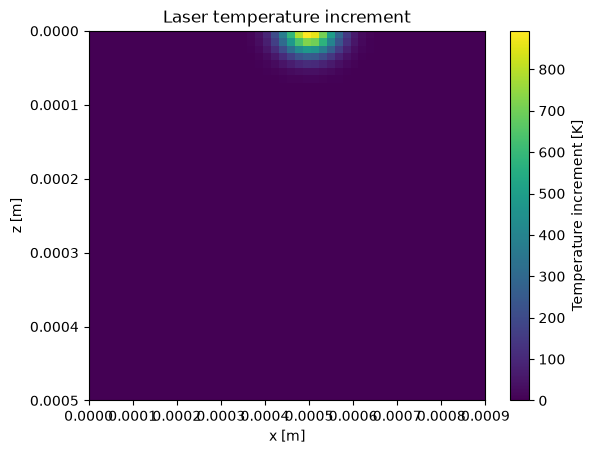

In [13]:
import matplotlib.pyplot as plt
from physics.heat_source import LaserSource

F.T = np.ones_like(F.T) * 303
laser = LaserSource(
                P = 500,    #[W]
                A = 0.8,    #[1]
                Cp = F.cp,  #[J/kg-K]
                a = 100*1e-6,    #[m] -> micrometer * 1e-6
                b = 100*1e-6,    #[m] ""
                c = 30 * 1e-6,   #[m] ""
                rho=F.rho,  #[kg/m3]
                k=F.k,      #[W/m3-K]
                V = 0.5,      #[m/s]
                t_prime = 0,
                delta_t = 1 # doesn't inform laser at the moment
        )

dT = laser.temperature_update(
    fields          = F, 
    mesh            = mesh, 
    current_time    = 0.001, 
    delta_time      = 1e-4
)


plt.figure()
plt.pcolormesh(mesh.x, mesh.z, dT, shading="auto")
plt.colorbar(label="Temperature increment [K]")
plt.xlabel("x [m]")
plt.ylabel("z [m]")
plt.gca().invert_yaxis()
plt.title("Laser temperature increment")
# plt.show()

In [ ]:
# for name, value in [
#     ("rho", F.rho),
#     ("Cp", F.cp),
#     ("k", F.k)
# ]:
#     print(
#         name,
#         "min:", np.min(value),
#         "max:", np.max(value)
#     )
T = 303
(1.57 + 0.016 * (T - 273) - (T - 273)**2 * 1e-6)*(1-0.45)**4